# Lab 6: whole-Re generalization, network depth and optimization

This additional CPU experiment learns **centreline profiles** from Ghia samples;
it does not solve a PDE, learn pressure, or validate a 2D field. Complete
[Lab 5: Ghia validation](W4_Lab5_All_Re_Ghia_Validation.ipynb) first. The earlier
CFD/field-surrogate notebooks retain their existing data and Reynolds range.

Inputs are normalized wall position, $\log_{10} Re-3$ and a u/v component tag.
Train on Re=100,1000,5000,10000; select architecture/optimizer/weights using only
Re=400; freeze the choice before scoring Re=3200 and 7500. All points from a Re
belong to one split. These public teaching tests are now disclosed: further tuning
against them is exploratory and requires a new independent test for a research claim.

We ran three initializations (7,23,61), five configurations, and 1200 joint
function/gradient evaluations per fit. Width is 24; compare 2 versus 5 hidden
layers (721 versus 2521 parameters), Adam, L-BFGS, and Adam then L-BFGS.
The last variant triples training weight at positions below 0.12 or above 0.88,
renormalizing each case/component to equal total weight. These are **regression
data weights**, not PINN PDE/boundary loss weights. Depth is not parameter matched.
Training uses Xavier initialization and tanh. Hard endpoint lifts enforce
$\hat u(t)=t+t(1-t)N_\theta$ and $\hat v(t)=t(1-t)N_\theta$.

Adam rescales each coordinate's first moment by its second moment and is a useful
initial stage. L-BFGS builds curvature information from parameter/gradient
differences; its line search needs a fixed deterministic objective. More layers
can represent sharper structure but also make optimization harder. Weighting
can prioritize boundary layers while worsening the core. **None is guaranteed
to beat interpolation.** The retained results below show both gains and losses.

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

In [2]:
frozen = course.verify_frozen_models(ROOT)
folder = ROOT/'results/cavity_ghia_allre'
scores = pd.read_csv(folder/'scores.csv')
timing = pd.read_csv(folder/'timing.csv')
display(pd.DataFrame([{'Re':int(k),'role':v} for k,v in frozen['roles'].items()]))
print('Frozen selection:', frozen['selected'], '|', frozen['selection'])
# First average u/v within a seed, then report seed mean and spread.
per_seed = scores.groupby(['model','Re','role','seed'])[['rmse_U','relative_l2']].mean().reset_index()
summary = per_seed.groupby(['model','Re','role']).agg(
    rmse_mean=('rmse_U','mean'), rmse_seed_sd=('rmse_U','std'),
    relative_l2_mean=('relative_l2','mean')).reset_index()
display(summary[summary.role=='test'])
display(timing.groupby('model').agg(parameters=('parameters','first'),
       evaluations=('evaluations','max'),median_seconds=('seconds','median')))
print('Timing is local and load-sensitive; equal evaluations are not equal FLOPs or time.')

Frozen selection: hybrid_5_wall | mean u/v RMSE on Re=400, averaged over predeclared seeds
Timing is local and load-sensitive; equal evaluations are not equal FLOPs or time.


,Re,role
0,100,train
1,400,validation
2,1000,train
3,3200,test
4,5000,train
5,7500,test
6,10000,train


,model,Re,role,rmse_mean,rmse_seed_sd,relative_l2_mean
3,adam_2,3200,test,0.033949,0.003324,0.085211
5,adam_2,7500,test,0.038002,0.001475,0.094761
10,hybrid_2,3200,test,0.039900,0.010207,0.102011
12,hybrid_2,7500,test,0.013904,0.001207,0.035263
17,hybrid_5,3200,test,0.026175,0.004951,0.067232
19,hybrid_5,7500,test,0.007462,0.002622,0.018877
24,hybrid_5_wall,3200,test,0.019739,0.002292,0.049757
26,hybrid_5_wall,7500,test,0.005627,0.000955,0.014048
31,lbfgs_2,3200,test,0.050537,0.032819,0.130786
33,lbfgs_2,7500,test,0.017614,0.009074,0.045065


,parameters,evaluations,median_seconds
model,,,
adam_2,721,1200,4.834419
hybrid_2,721,1200,0.414815
hybrid_5,2521,1200,0.977209
hybrid_5_wall,2521,1200,0.689110
lbfgs_2,721,1200,17.317950


Re=100, train: physical profiles and signed discrepancies
Re=400, validation: physical profiles and signed discrepancies
Re=1000, train: physical profiles and signed discrepancies
Re=3200, test: physical profiles and signed discrepancies
Re=5000, train: physical profiles and signed discrepancies
Re=7500, test: physical profiles and signed discrepancies
Re=10000, train: physical profiles and signed discrepancies


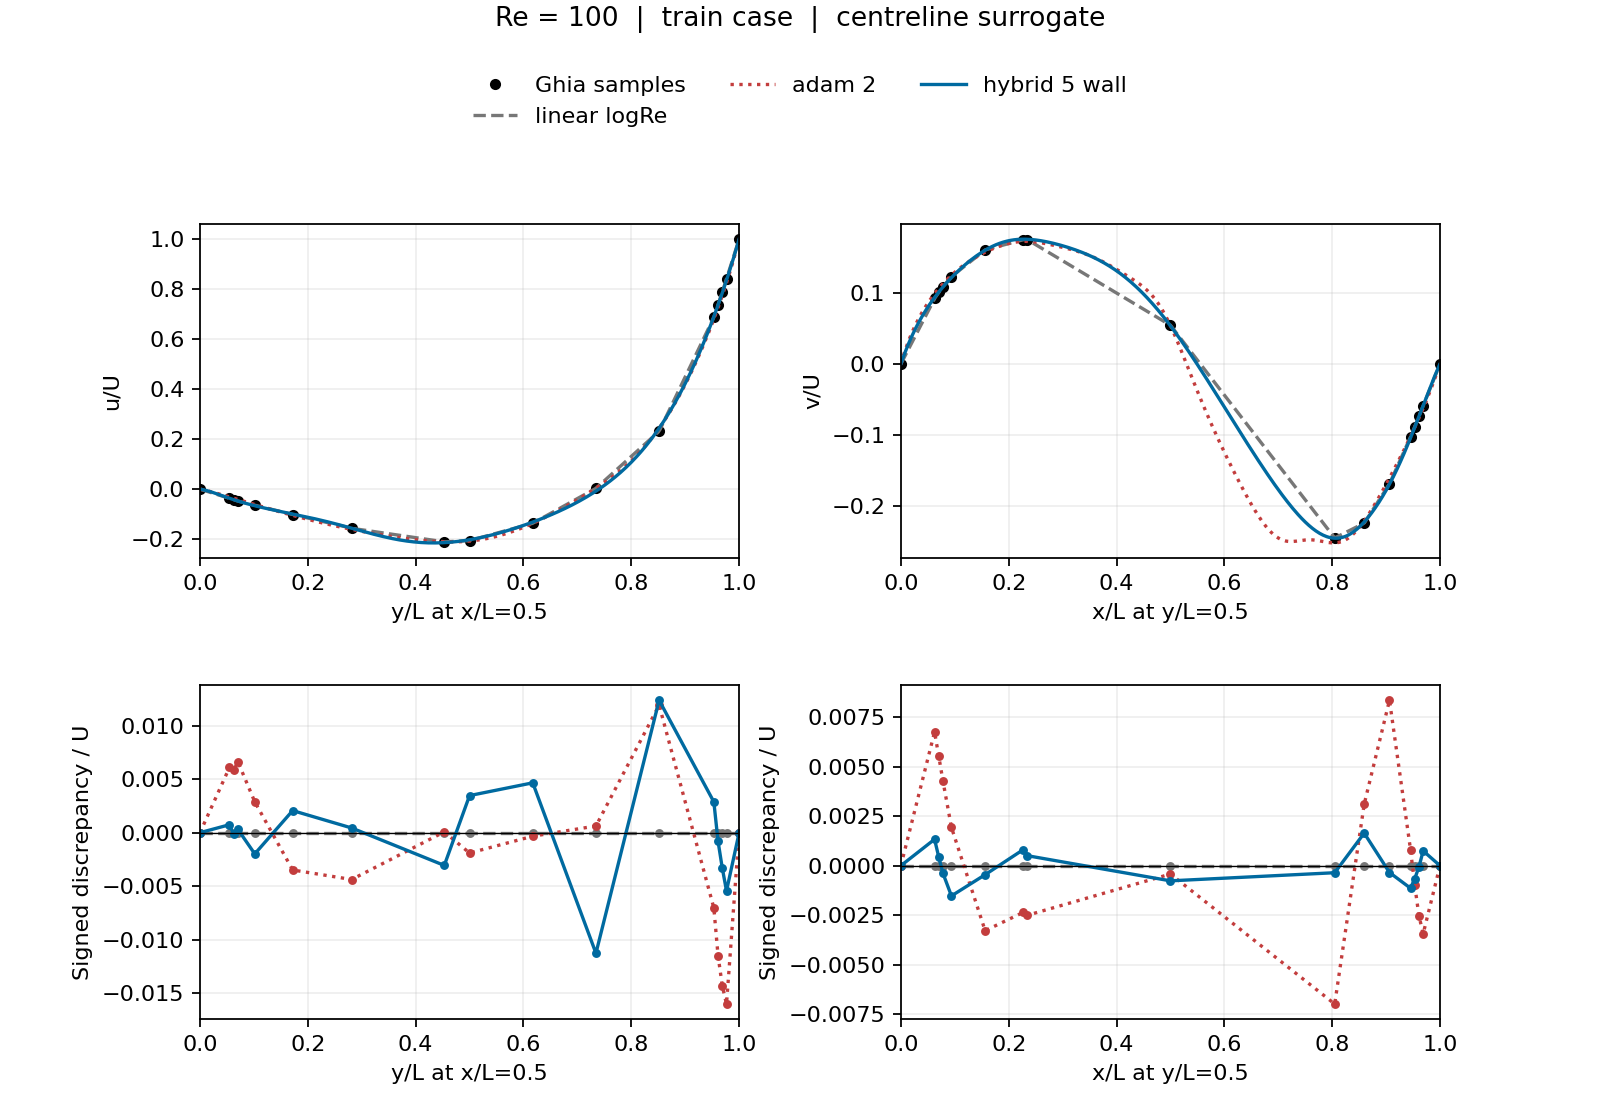

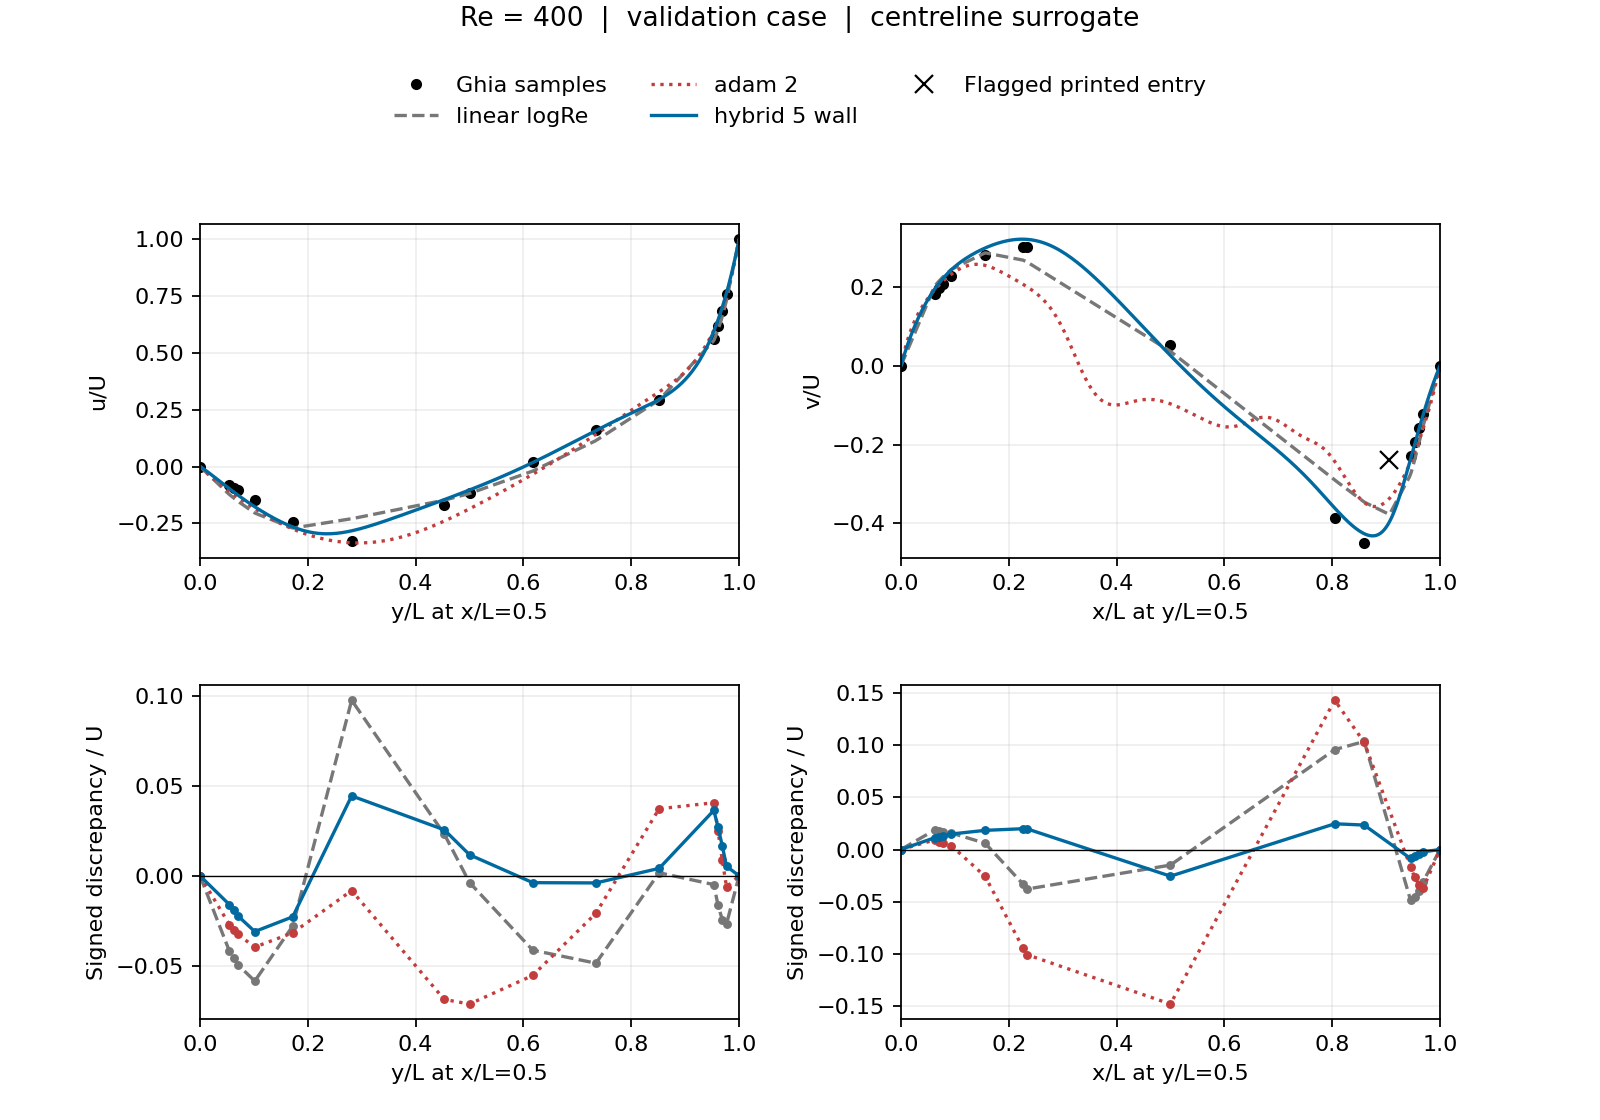

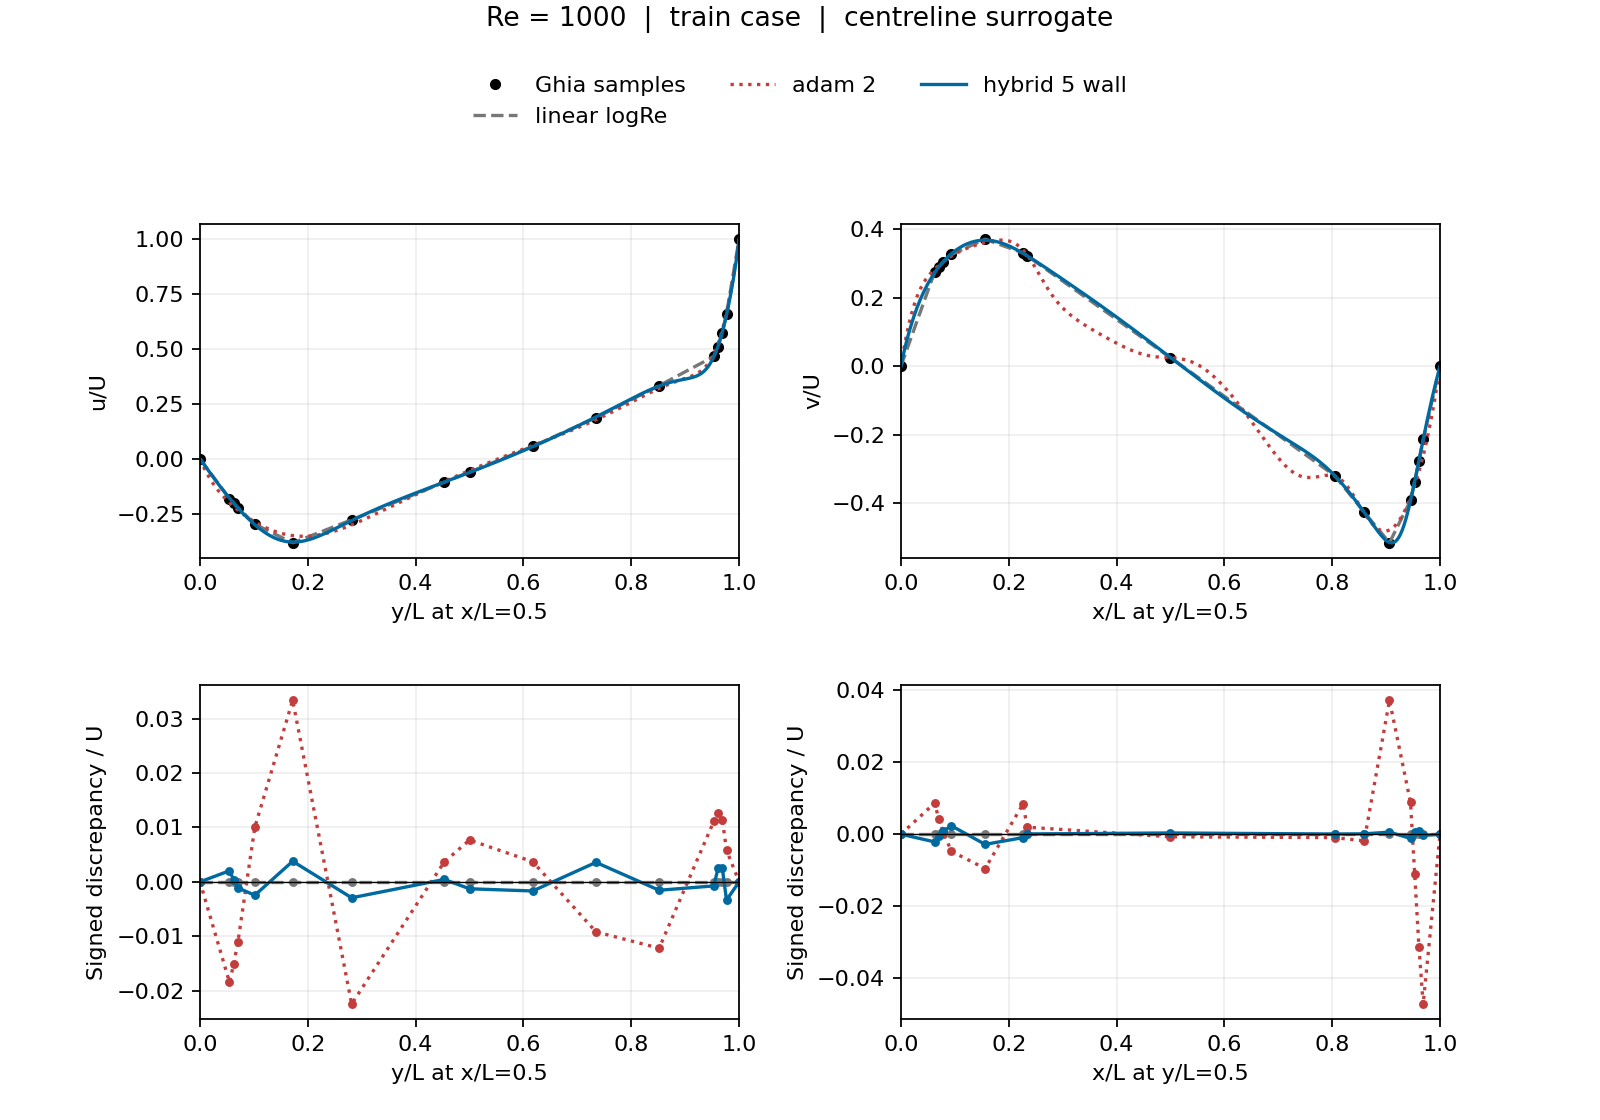

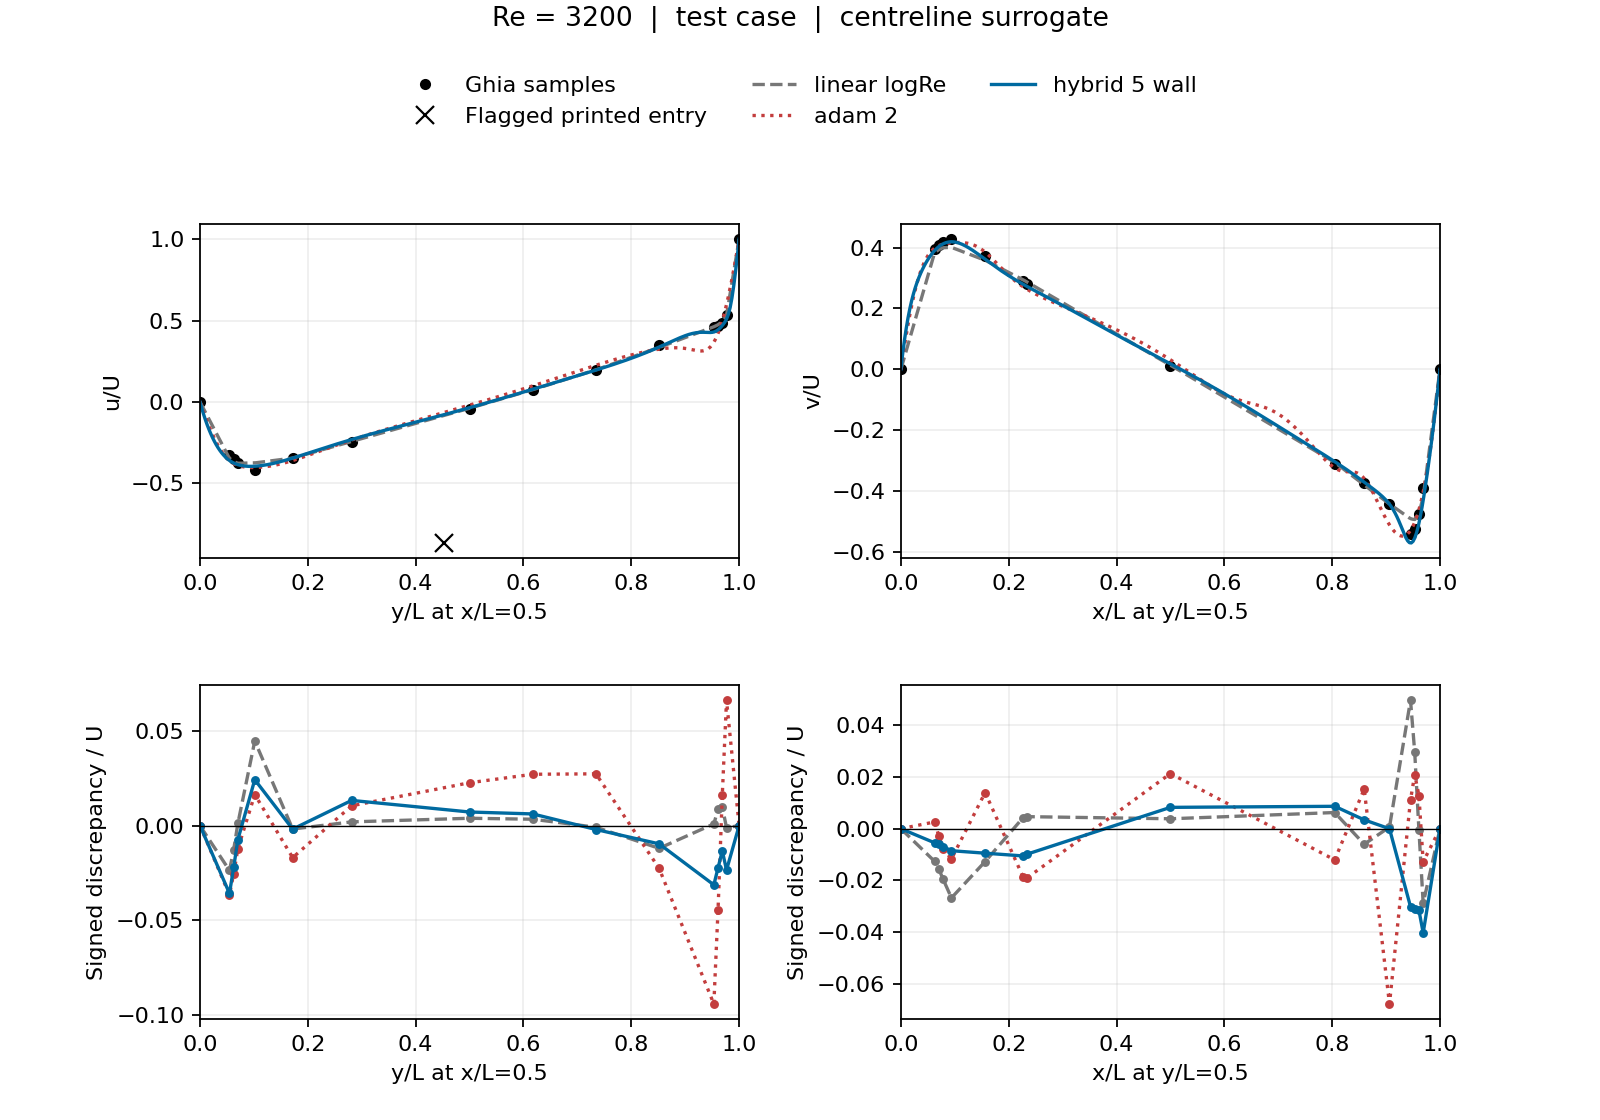

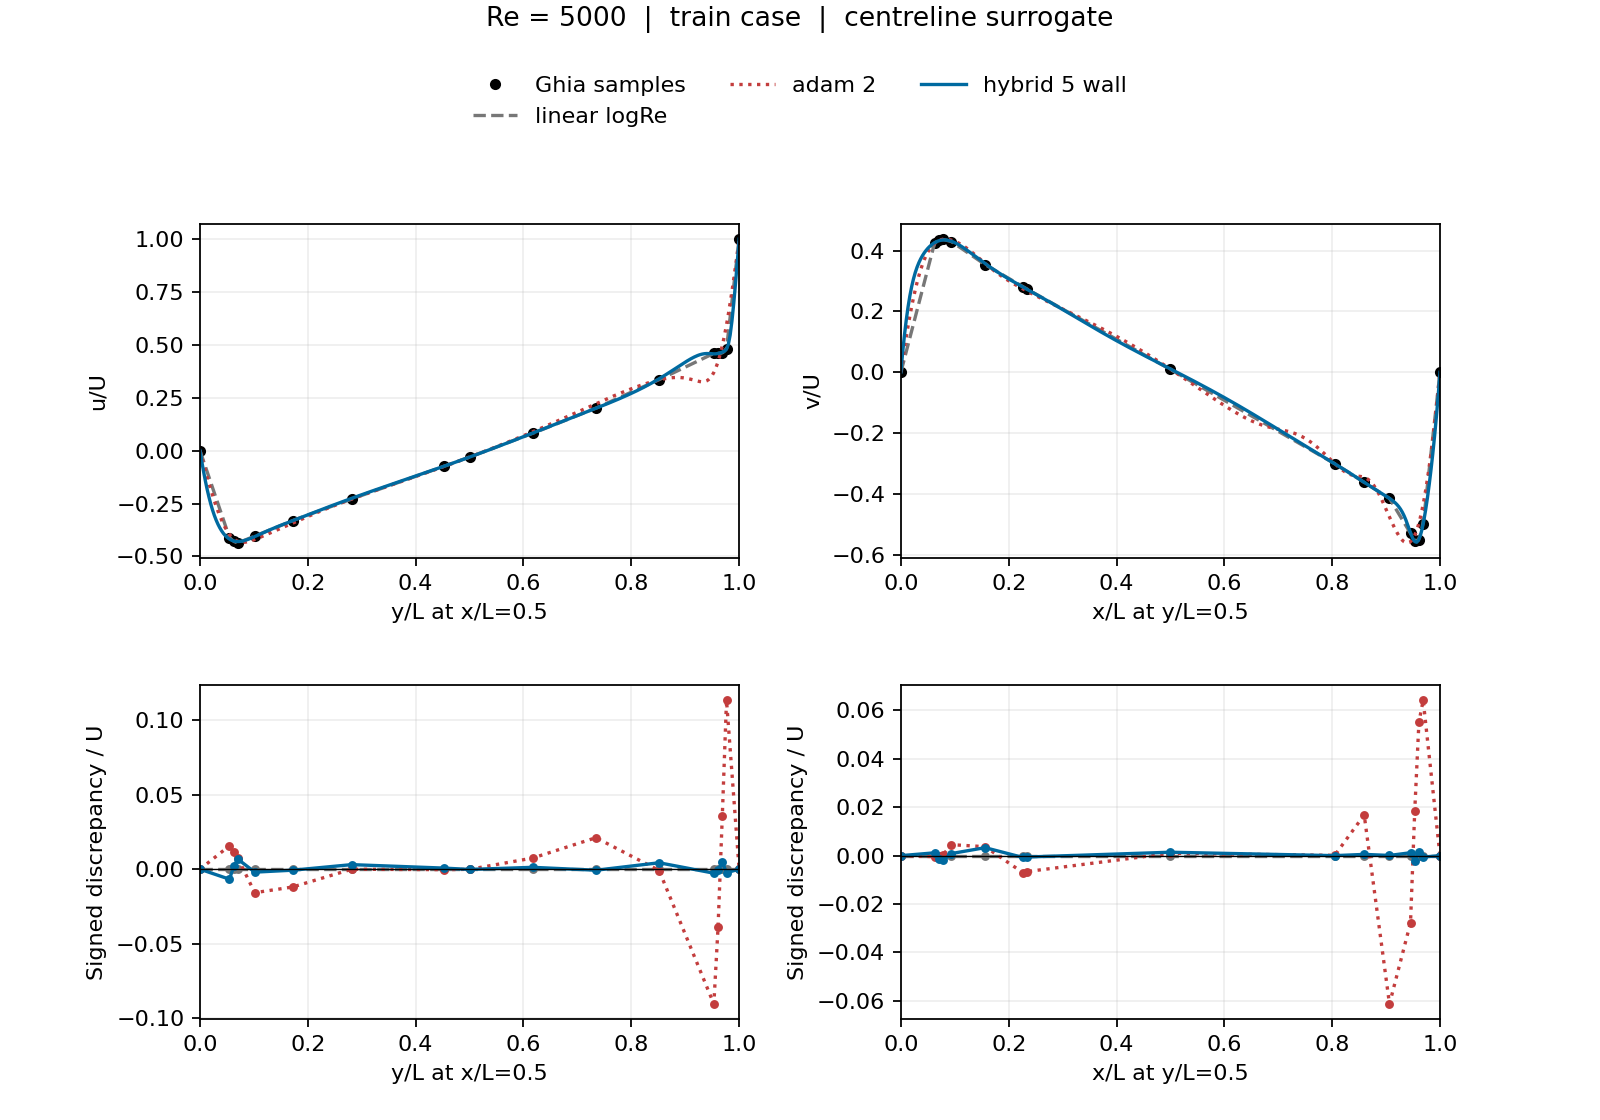

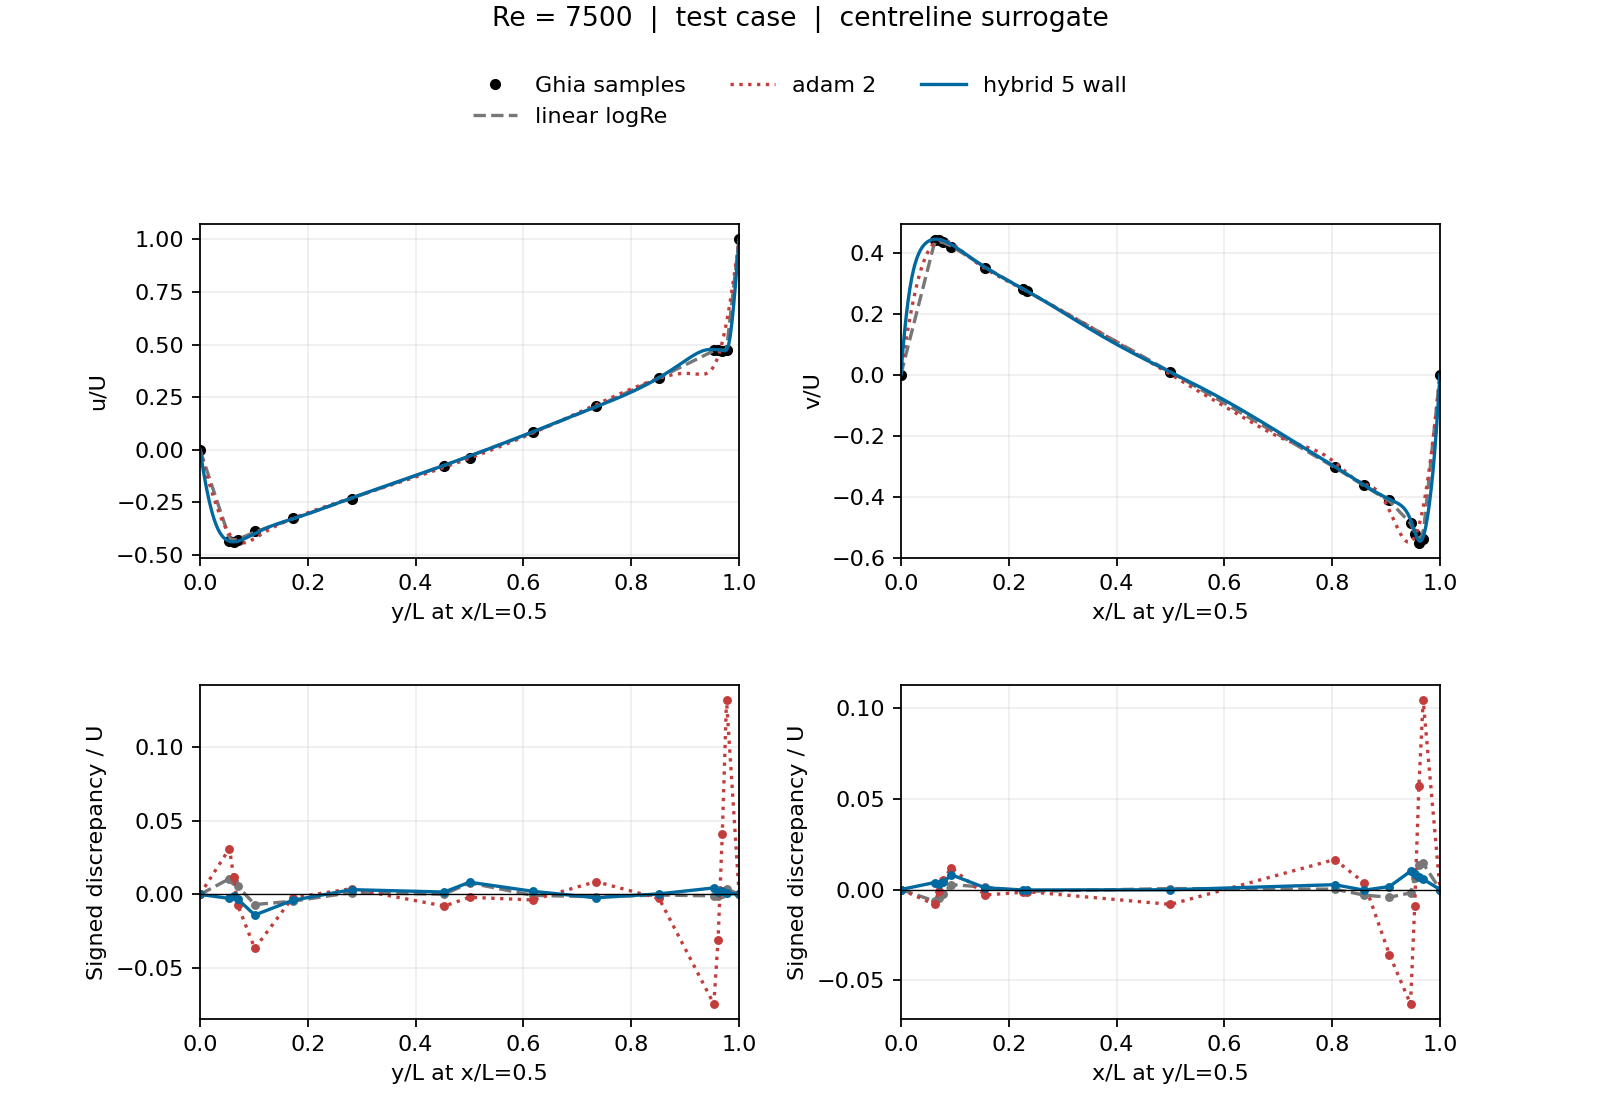

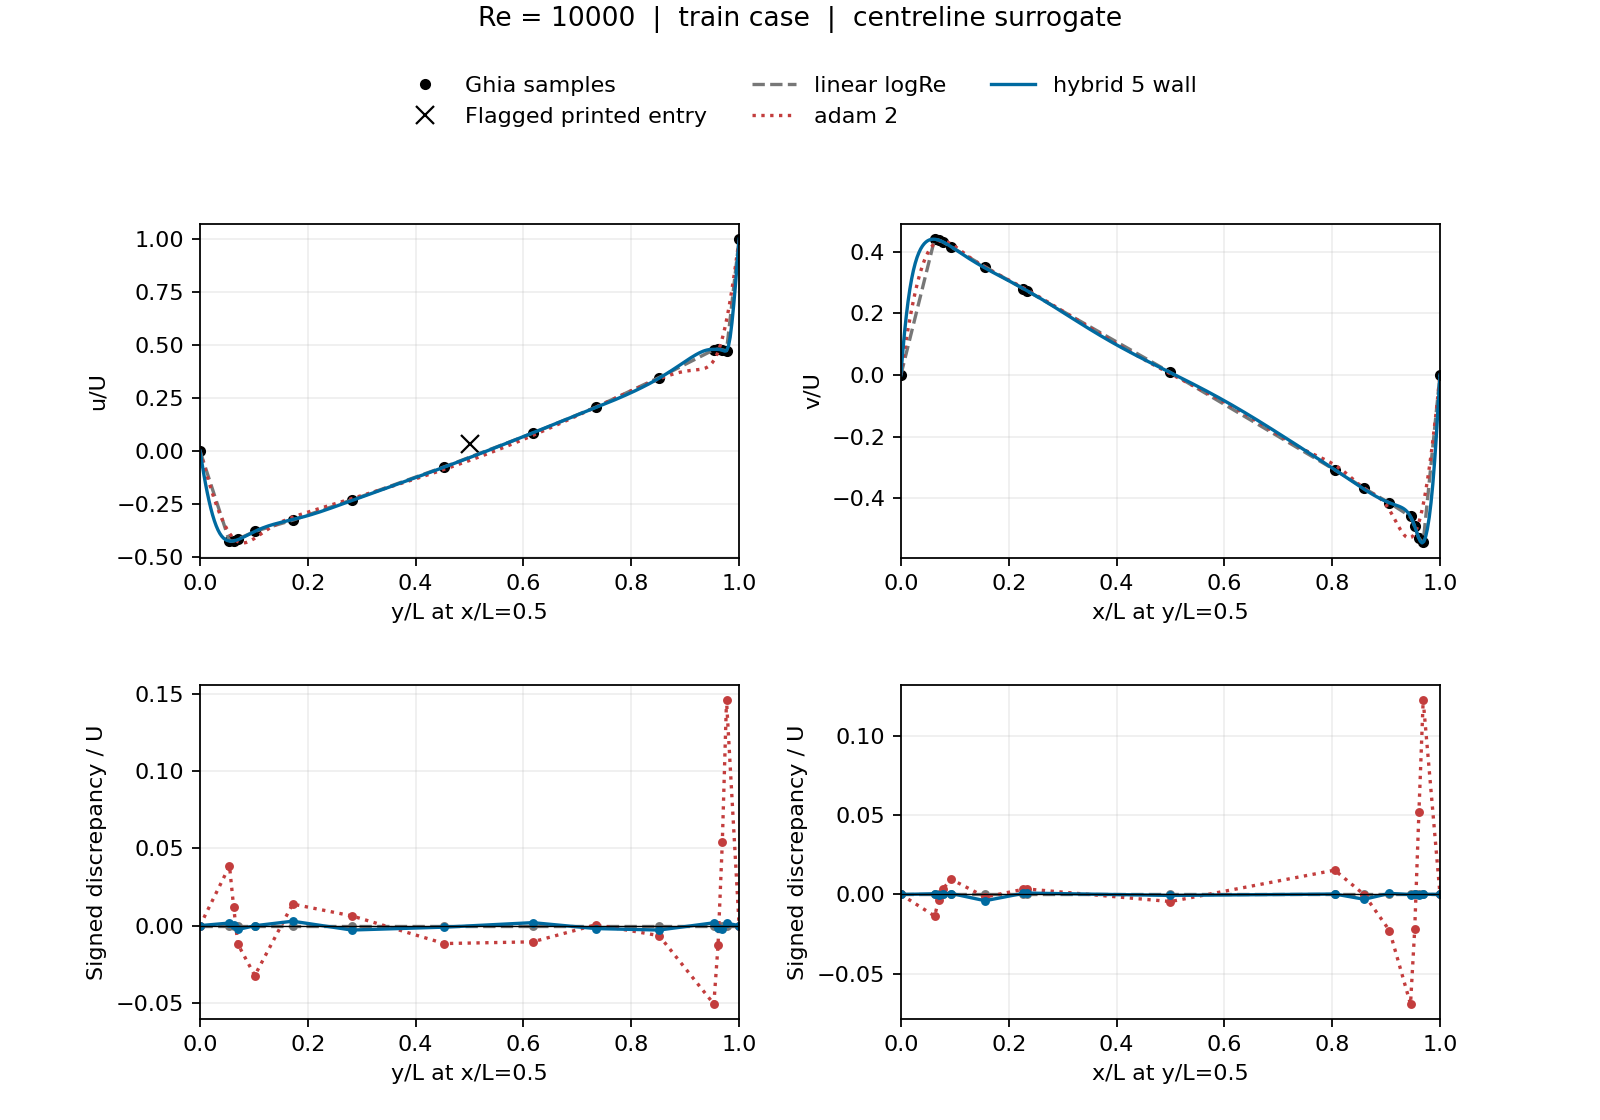

In [3]:
for re in ghia.REYNOLDS:
    print(f'Re={re}, {ghia.case_roles()[re]}: physical profiles and signed discrepancies')
    display(Image(filename=str(folder/f're{re}_profiles.png'), width=800))

### What the retained experiment found

Re=400 selected the five-layer, wall-weighted Adam-to-L-BFGS variant. On the two
test cases its mean u/v RMSE is about 0.01974 U (Re=3200) and 0.00563 U (Re=7500).
The two-layer Adam baseline gives 0.03395 U and 0.03800 U. However, piecewise linear
interpolation in **log Re**, using only training cases and the same screened
samples, gives 0.01629 U and 0.00518 U: it wins both tests. The network improves
on its neural baseline but does not justify replacing this simple method.
These are averages of the per-seed, per-component errors, not errors of an ensemble.
The plotted neural curves are three-seed means. Raw printed-data sensitivity
scores, including the suspicious Re=3200 entry, remain in `scores.csv`.

### Specific student tasks: architecture, optimization and weights

1. Reproduce the **test table above** from the CSV and show the standard deviation
   across seeds. Compare Adam-2 with hybrid-2, hybrid-2 with hybrid-5, and hybrid-5
   with hybrid-5-wall. State what changes in each comparison and what is confounded.
2. Use the u/v plots to locate the largest signed error in each held-out case.
   Explain why a lower training loss need not imply a better withheld-Re profile.
3. Before running a new model, declare width, depth, seed list, learning rate,
   weighting and budget. Tune only on Re=400. Try widths chosen to approximately
   match parameter count; also compare wall-clock cost with warm-up and repeats.
4. Vary the wall weight from 1 to 3 or 5 and report wall and core errors separately.
   Explain why a wall-weighted training loss must not replace an unweighted audit.
5. Compare interpolation in Re with interpolation in log Re. Choose that convention
   using validation only, then freeze it. Do not claim either is a CFD solver.
6. For a future full-field DeepONet, first obtain independently admitted fields
   for every train/validation/test Re. Keep all grid points from one Re together;
   fit normalization and the POD basis on training fields only. Compare against
   field interpolation and POD regression before interpreting network depth.

In [4]:
# A small optional new training run, kept separate from the frozen comparison.
TRAIN_NEW_PROFILE_MODEL = False
if TRAIN_NEW_PROFILE_MODEL:
    from flowmllab.ghia_surrogate import ModelConfig, fit, predict
    trial_config = ModelConfig(name='student_trial',depth=3,width=20,
                               optimizer='hybrid',weighting='uniform',evaluations=1200)
    trial = fit(trial_config,seed=17)
    reference = ghia.reference(400)
    for component in ('u','v'):
        t=reference['y' if component=='u' else 'x']; keep=ghia.valid_mask(400,component)
        error=predict(trial,400,t,component)-reference[component]
        print(component,'validation RMSE/U',np.sqrt(np.mean(error[keep]**2)))
else:
    print('Showing retained runs; no test-informed retraining.')

Showing retained runs; no test-informed retraining.
